<a href="https://colab.research.google.com/github/elhaddarsaid/MNIST-Digit-Recognition/blob/main/MNIST_Digit_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
!pip3 install tensorflow
!pip install importlib_resources

In [22]:
!pip3 install tensorflow_datasets

In [23]:
!pip3 install matplotlib

In [27]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np

In [28]:
(db_en,db_te),info=tfds.load('mnist',split=['train','test'],with_info=True,as_supervised=True)

In [9]:
info

tfds.core.DatasetInfo(
    name='mnist',
    full_name='mnist/3.0.1',
    description="""
    The MNIST database of handwritten digits.
    """,
    homepage='http://yann.lecun.com/exdb/mnist/',
    data_dir='/root/tensorflow_datasets/mnist/3.0.1',
    file_format=tfrecord,
    download_size=11.06 MiB,
    dataset_size=21.00 MiB,
    features=FeaturesDict({
        'image': Image(shape=(28, 28, 1), dtype=uint8),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=10),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'test': <SplitInfo num_examples=10000, num_shards=1>,
        'train': <SplitInfo num_examples=60000, num_shards=1>,
    },
    citation="""@article{lecun2010mnist,
      title={MNIST handwritten digit database},
      author={LeCun, Yann and Cortes, Corinna and Burges, CJ},
      journal={ATT Labs [Online]. Available: http://yann.lecun.com/exdb/mnist},
      volume={2},
      year

In [29]:
from numpy._core.numeric import inf
def normaliser(image,label):
  return tf.cast(image,tf.float32)/255,label
db_en=db_en.map(normaliser)
db_te=db_te.map(normaliser)
db_en=db_en.shuffle(info.splits['train'].num_examples)
db_en=db_en.batch(128)
db_te=db_te.batch(128)

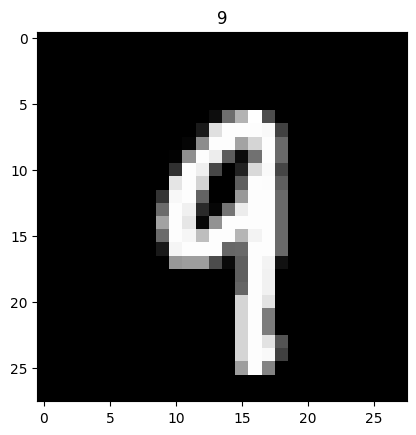

In [30]:
def afficher_image(image,label):
  plt.imshow(image,cmap='gray')
  plt.title(f'{label}')
  plt.show()
for image,label in db_en.take(1):
  afficher_image(image[0],label[0])

In [31]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28,28,1)),
    tf.keras.layers.Dense(128,activation='relu'),
    tf.keras.layers.Dense(10,activation='softmax')
])
model.compile(loss='sparse_categorical_crossentropy',optimizer='adam',metrics=['accuracy'])
model.fit(db_en,epochs=5,validation_data=db_te)

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9020 - loss: 0.3568 - val_accuracy: 0.9453 - val_loss: 0.1928
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9538 - loss: 0.1626 - val_accuracy: 0.9617 - val_loss: 0.1337
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.9661 - loss: 0.1179 - val_accuracy: 0.9694 - val_loss: 0.1056
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9745 - loss: 0.0907 - val_accuracy: 0.9709 - val_loss: 0.0958
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9793 - loss: 0.0729 - val_accuracy: 0.9738 - val_loss: 0.0856


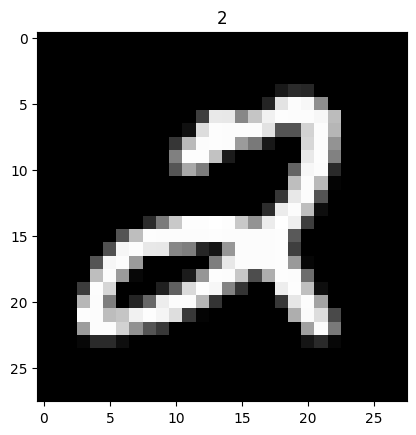

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
2 [5.4281628e-09 3.7596095e-07 9.9998170e-01 4.4995031e-06 1.2505153e-05
 3.5524423e-09 7.3250725e-08 2.6236970e-09 6.6187783e-07 4.4743698e-09]


In [39]:
for image ,label in db_te.take(1):
  afficher_image(image[0],label[0])
  print(np.argmax(model.predict(image)[0]),model.predict(image)[0])
